# Построение baseline-модели для кейса №5 Регрессионое прогнозировнаие времени доставки еды

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score


## Часть 1. Загрузка данных и фильтрация

По итогам EDA мы выяснили, что для прогнозирования времени доставки нам нужны только завершенные заказы (статус `Completed`). 
Кроме того, мы очищаем данные от логических аномалий:
1. Удаляем заказы, где время готовки было больше или равно общему времени доставки (это физически невозможно).
2. Удаляем заказы с нереалистичной скоростью курьера (выше 60 км/ч), так как это вносит лишний шум в модель.

In [22]:
df = pd.read_csv('../../Data/food_delivery_orders_dataset.csv')
df_delivered = df[df['order_status'] == 'Completed'].copy()

df_delivered['pure_delivery_time'] = df_delivered['actual_delivery_time_minutes'] - df_delivered['restaurant_preparation_time_minutes']
df_delivered['pure_speed_kmh'] = df_delivered['distance_km'] / (df_delivered['pure_delivery_time'] / 60)

rows_before_cleaning = len(df_delivered)

df_delivered = df_delivered[
    (df_delivered['pure_delivery_time'] > 0) & 
    (df_delivered['pure_speed_kmh'] <= 60)
].copy()

print(f"Исходный размер датасета: {len(df)} строк")
print(f"Строк после полной очистки: {len(df_delivered)} строк, {df_delivered.shape[1]} столбцов")
print(f"Удалено аномалий: {rows_before_cleaning - len(df_delivered)} строк")
print(f"Пропусков в целевом признаке: {df_delivered['actual_delivery_time_minutes'].isna().sum()}")

Исходный размер датасета: 50000 строк
Строк после полной очистки: 48914 строк, 39 столбцов
Удалено аномалий: 218 строк
Пропусков в целевом признаке: 0


## Часть 2. Подготовка признаков

Для обучения модели мы отбираем ключевые признаки, которые показали свою важность в EDA: расстояние, время приготовления, количество блюд в заказе, уровень пробок и погода.

Поскольку линейная регрессия умеет работать только с числами, текстовые признаки (погода и пробки) мы переводим в числовой формат с помощью `pd.get_dummies`. Параметр `drop_first=True` помогает избежать дублирования информации (мультиколлинеарности).

In [ ]:
features = [
    'distance_km', 
    'restaurant_preparation_time_minutes', 
    'items_count', 
    'traffic_level', 
    'weather'
]

X = df_delivered[features].copy()
y = df_delivered['actual_delivery_time_minutes']

X = pd.get_dummies(X, drop_first=True)

print(f"Итоговый размер матрицы X: {X.shape[0]} строк, {X.shape[1]} столбцов")
display(x.head(3))

Итоговый размер матрицы X: 48914 строк, 8 столбцов


,distance_km,restaurant_preparation_time_minutes,items_count,traffic_level_Low,traffic_level_Medium,weather_Cloudy,weather_Rain,weather_Storm
0,1.1,25,4,False,True,False,True,False
1,2.5,12,2,False,False,True,False,False
2,11.8,11,1,False,False,True,False,False


## Часть 3. Обучение базовой модели и метрики

Разделяем данные на обучающую и тестовую выборки в пропорции 80/20. Параметр `random_state=42` фиксирует случайность, чтобы результаты можно было воспроизвести.

Обучаем модель `LinearRegression` и оцениваем её качество по двум метрикам:
- **MAE (Mean Absolute Error)**: показывает, на сколько минут в среднем ошибается наша модель.
- **R² (коэффициент детерминации)**: показывает, какую долю разброса данных смогла объяснить модель (чем ближе к 1, тем лучше).

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lm = LinearRegression()
lm.fit(X_train, y_train)

y_pred = lm.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Средняя абсолютная ошибка (MAE): {mae:.2f} минут")
print(f"Коэффициент детерминации (R²): {r2:.3f}")

Средняя абсолютная ошибка (MAE): 2.74 минут
Коэффициент детерминации (R²): 0.938


## Часть 4. Масштабирование и оценка важности признаков

Как мы обсуждали на вебинаре, сравнивать коэффициенты регрессии «в лоб» нельзя, так как признаки измеряются в разных единицах (километры, минуты, штуки). 

Для честного сравнения мы применяем `StandardScaler`. Обучаем его строго на тренировочной выборке, чтобы избежать утечки данных из теста. После масштабирования мы можем отсортировать коэффициенты по модулю и увидеть, какой признак оказывает наибольшее влияние на время доставки.

In [42]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lm_scaled = LinearRegression()
lm_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = lm_scaled.predict(X_test_scaled)

coef_df = pd.DataFrame({
    'Признак': X.columns,
    'Влияние (коэффициент)': lm_scaled.coef_
})

coef_df['Влияние (коэффициент)'] = coef_df['Влияние (коэффициент)'].round(2)

coef_df['abs_coef'] = coef_df['Влияние (коэффициент)'].abs()
coef_df = coef_df.sort_values(by='abs_coef', ascending=False).drop(columns='abs_coef')

print("Рейтинг важности признаков (после масштабирования):")
display(coef_df)

Рейтинг важности признаков (после масштабирования):


,Признак,Влияние (коэффициент)
0,distance_km,11.24
1,restaurant_preparation_time_minutes,7.33
3,traffic_level_Low,-4.33
4,traffic_level_Medium,-2.47
6,weather_Rain,2.13
7,weather_Storm,2.12
5,weather_Cloudy,0.77
2,items_count,0.01


## Часть 5. Визуальная оценка точности модели

Помимо метрик, полезно посмотреть на предсказания модели глазами. Построим точечный график (scatterplot), где:
- По оси X отложено **реальное время** доставки.
- По оси Y — **предсказанное моделью** время.

Красная пунктирная линия — это «идеальный прогноз» (где предсказание в точности совпадает с реальностью). Чем ближе фиолетовые точки будут лежать к этой красной линии, тем точнее работает наша модель. Если точки сильно разбросаны, значит, модель часто ошибается.

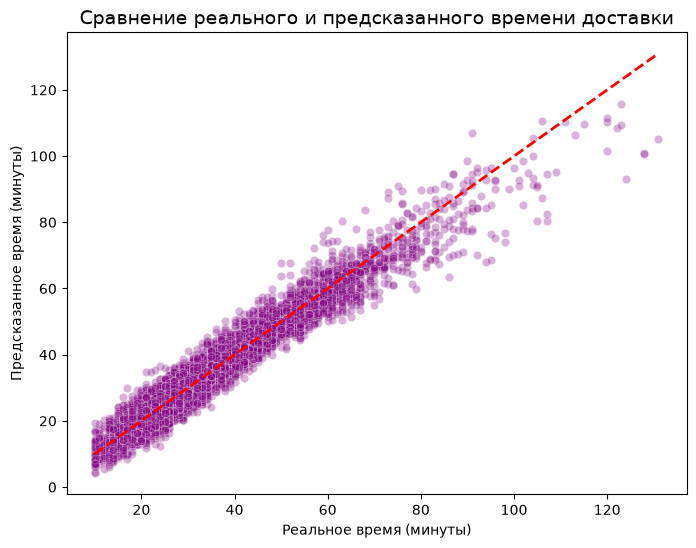

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3, color='purple')

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2)

plt.title('Сравнение реального и предсказанного времени доставки', fontsize=14)
plt.xlabel('Реальное время (минуты)')
plt.ylabel('Предсказанное время (минуты)')
plt.show()

**Вывод по графику:**
На графике видно, что основная масса точек сгруппировалась вдоль красной линии (особенно в диапазоне от 20 до 45 минут). Это хороший признак: модель улавливает общую закономерность и в большинстве случаев предсказывает время достаточно точно. 
Однако есть и выбросы (точки, которые далеко от линии). Например, в правом верхнем углу модель может сильно занижать время, если реальный заказ занял более 80 минут (модель не может предсказать форс-мажоры). В целом для базовой модели картина хорошая.

## Часть 6. Диагностика модели: анализ остатков

Метрики показывают общую точность, но не говорят о характере ошибок. Остатки (`residuals`) — это разница между реальным временем и прогнозом модели (`y_test - y_pred`).

Идеальная модель должна ошибаться случайно: её остатки должны быть распределены нормально (как «колокол») с центром ровно в нуле. 
Если график смещен влево или вправо, значит, модель систематически завышает или занижает прогнозы.

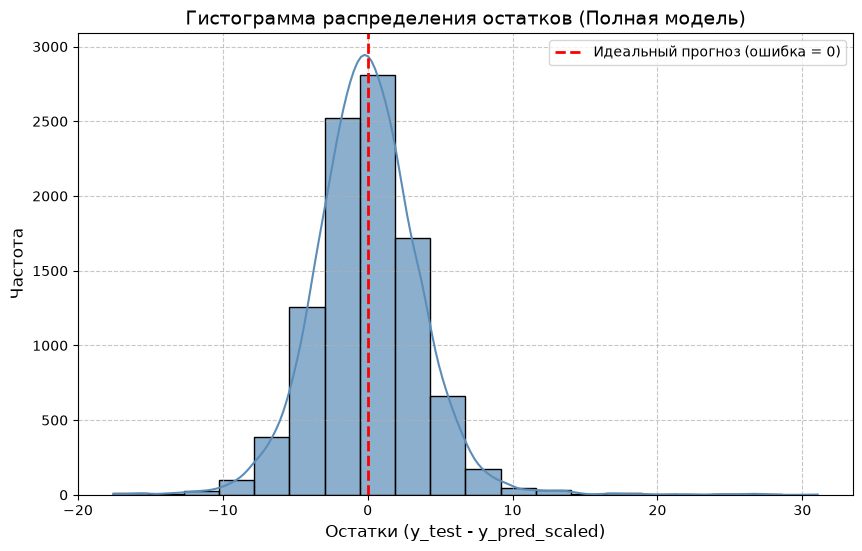

In [ ]:
residuals = y_test - y_pred_scaled

plt.figure(figsize=(10, 6))
sns.histplot(residuals, bins=20, kde=True, color='#5B8DB8', edgecolor='black', alpha=0.7)
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Идеальный прогноз (ошибка = 0)')

plt.title('Гистограмма распределения остатков (Полная модель)', fontsize=14)
plt.xlabel('Остатки (y_test - y_pred_scaled)', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

**Вывод по графику остатков:**  
На графике видно, что распределение ошибок модели похоже на нормальное («колокол»). Пик распределения находится практически ровно на нуле (красная линия), что говорит об отсутствии систематического смещения — модель не склонна постоянно завышать или занижать время. Основная масса ошибок укладывается в узкий диапазон от -5 до +5 минут, что подтверждает хорошее значение метрики MAE. Однако справа виден длинный хвост с ошибками до +20 и +30 минут. Это случаи, когда фактическое время оказалось намного больше прогноза. Вероятно, это редкие заказы с форс-мажорами (сильный шторм или аварийные пробки), которые эта линейная модель не смогла предугадать.  

## Выводы по baseline-модели

1. **Качество модели:** Базовая линейная регрессия показала MAE = *2.74* минут и R² = *0.938*. Это хороший отправной результат. 
2. **Важность признаков:** После масштабирования мы подтвердили выводы EDA. Наибольшее влияние на время доставки оказывают **расстояние** и **время приготовления в ресторане**. Влияние погоды и количества блюд второстепенно.
3. **Анализ остатков:** Гистограмма остатков показывает, что распределение ошибок близко к нормальному, однако пик слегка смещен. Это означает, что на коротких дистанциях модель может немного завышать прогноз, но в целом она корректно улавливает основные закономерности.